# TextCNN Baseline

In [1]:
from contextlib import redirect_stdout
from io import StringIO

import torch
import matplotlib.pyplot as plt
from IPython.display import display
from torch import nn
import torch.nn.functional as F
from sklearn.metrics import accuracy_score, f1_score

from text_data import create_dataloader, PAD_ID
from utils import get_device, plot_history
from train import train_model

DATA_DIR = "data/merged"
GENRE = "FPS"

torch.manual_seed(42)

train_set, val_set, test_set, vocab = create_dataloader(
    DATA_DIR,
    genre=GENRE,
    batch_size=64       
)

## Define TextCNN Model

In [2]:
class TextCNN(nn.Module):
    """Classify reviews with parallel convolutions and max pooling."""
    def __init__(self, vocab_size, embed_size, kernel_size, num_channels):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embed_size,
            padding_idx=PAD_ID
        )
        self.dropout = nn.Dropout(0.5)
        self.decoder = nn.Linear(sum(num_channels), 2)
        self.pool = nn.AdaptiveMaxPool1d(1)
        self.relu = nn.ReLU()
    
        # create multiple conv layers
        self.convs = nn.ModuleList()
        for c, k in zip(num_channels, kernel_size):
            self.convs.append(nn.Conv1d(embed_size, c, k))

    def forward(self, inputs, lengths=None):
        # embeddings shape: (batch_size, num_tokens, embed_size)
        embeddings = self.embedding(inputs)
        # Conv1d expects (batch, channels, length)
        embeddings = embeddings.permute(0, 2, 1)
        
        # tensor shape of each 1d conv layer after pooling: (batch_size, num_channels, 1)
        encoding = torch.cat([
            torch.squeeze(self.relu(self.pool(conv(embeddings))), dim=-1)
            for conv in self.convs], dim=1)
        outputs = self.decoder(self.dropout(encoding))
        return outputs

In [3]:
embed_size, kernel_size, num_channels = 100, [3, 4, 5], [100, 100, 100]

net = TextCNN(len(vocab), embed_size, kernel_size, num_channels)

def init_weights(m):
    if type(m) in (nn.Linear, nn.Conv1d):
        nn.init.xavier_uniform_(m.weight)

net.apply(init_weights)

TextCNN(
  (embedding): Embedding(7090, 100, padding_idx=0)
  (dropout): Dropout(p=0.5, inplace=False)
  (decoder): Linear(in_features=300, out_features=2, bias=True)
  (pool): AdaptiveMaxPool1d(output_size=1)
  (relu): ReLU()
  (convs): ModuleList(
    (0): Conv1d(100, 100, kernel_size=(3,), stride=(1,))
    (1): Conv1d(100, 100, kernel_size=(4,), stride=(1,))
    (2): Conv1d(100, 100, kernel_size=(5,), stride=(1,))
  )
)

Train loss: 0.125 | Train accuracy: 0.959 | Val accuracy: 0.828
Training on: mps
Average speed: 267649 tokens/sec


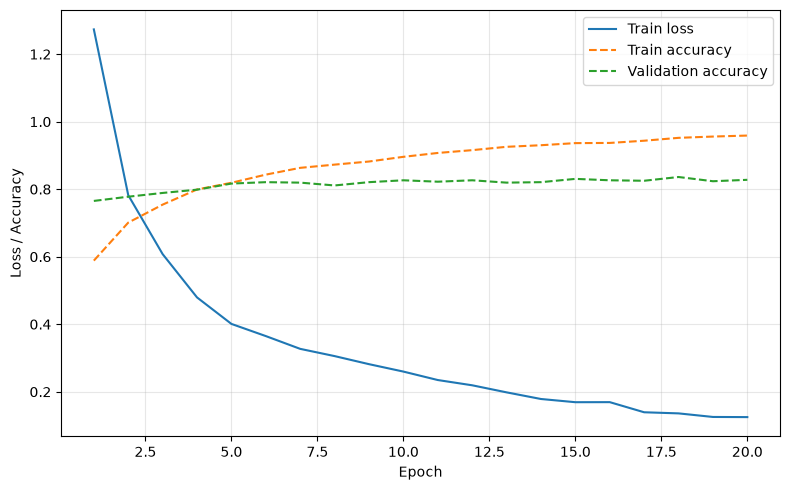

In [4]:
device = get_device()

# move model to device
net = net.to(device)

loss = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(net.parameters(), lr =1e-3)

training_output = StringIO()
status_display = display({"text/plain": ""}, raw=True, display_id=True)

fig, ax = plt.subplots(figsize=(8, 5))
plot_display = display(fig, display_id=True)
plt.close(fig)


def update_plot(history):
    """Refresh the training curves after each epoch."""
    status_display.update({"text/plain": training_output.getvalue()}, raw=True)
    plot_history(history, ax=ax)
    plot_display.update(fig)


with redirect_stdout(training_output):
    metric_history = train_model(
        model=net,
        train_loader=train_set,
        val_loader=val_set,
        loss_fn=loss,
        optimizer=optimizer,
        num_epochs=20,
        device=device,
        on_epoch_end=update_plot,
    )

last_metrics = metric_history[-1]
final_results = (
    f"Train loss: {last_metrics['train']['loss']:.3f} | "
    f"Train accuracy: {last_metrics['train']['accuracy']:.3f} | "
    f"Val accuracy: {last_metrics['val']['accuracy']:.3f}\n"
)
status_display.update(
    {"text/plain": final_results + training_output.getvalue()}, raw=True
)